In [103]:
# Importar las librerías necesarias
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Configurar el tamaño de las gráficas
plt.rcParams['figure.figsize'] = (12, 5)

print("Librerías cargadas correctamente")

Librerías cargadas correctamente


In [104]:
# Configuración de la señal
frecuencia_muestreo = 1000
duracion = 2

# Crear el eje de tiempo
t = np.linspace(0, duracion,
                frecuencia_muestreo * duracion,
                endpoint=False)

# Crear una señal compuesta por tres frecuencias
senal_original = (
    np.sin(2 * np.pi * 5 * t) +
    0.7 * np.sin(2 * np.pi * 50 * t) +
    0.5 * np.sin(2 * np.pi * 150 * t)
)

# Agregar ruido aleatorio
np.random.seed(42)
ruido = np.random.normal(0, 0.5, len(t))
senal_ruidosa = senal_original + ruido

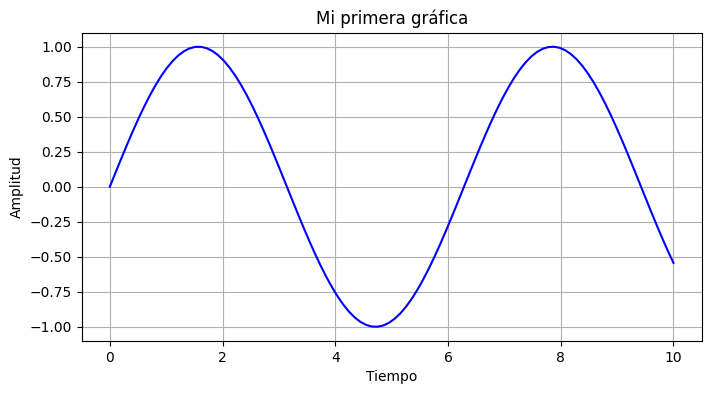

In [105]:

import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 10, 100)
y = np.sin(x)

plt.figure(figsize=(8, 4))
plt.plot(x, y, color="blue")
plt.title("Mi primera gráfica")
plt.xlabel("Tiempo")
plt.ylabel("Amplitud")
plt.grid(True)
plt.show()


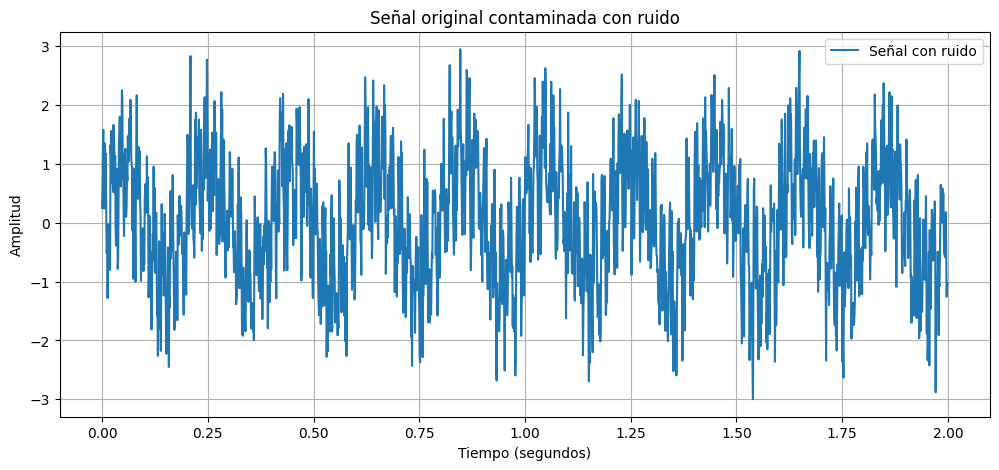

In [106]:

# 1. Configuración de la señal
frecuencia_muestreo = 1000
duracion = 2

# 2. Crear el eje del tiempo
t = np.linspace(0, duracion,
                frecuencia_muestreo * duracion,
                endpoint=False)

# 3. Crear una señal con tres frecuencias
senal_original = (
    np.sin(2 * np.pi * 5 * t) +
    0.7 * np.sin(2 * np.pi * 50 * t) +
    0.5 * np.sin(2 * np.pi * 150 * t)
)

# 4. Agregar ruido aleatorio
np.random.seed(42)
ruido = np.random.normal(0, 0.5, len(t))
senal_ruidosa = senal_original + ruido

# 5. Graficar la señal
plt.figure(figsize=(12, 5))
plt.plot(t, senal_ruidosa, label="Señal con ruido")
plt.title("Señal original contaminada con ruido")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.legend()
plt.grid()
plt.show()


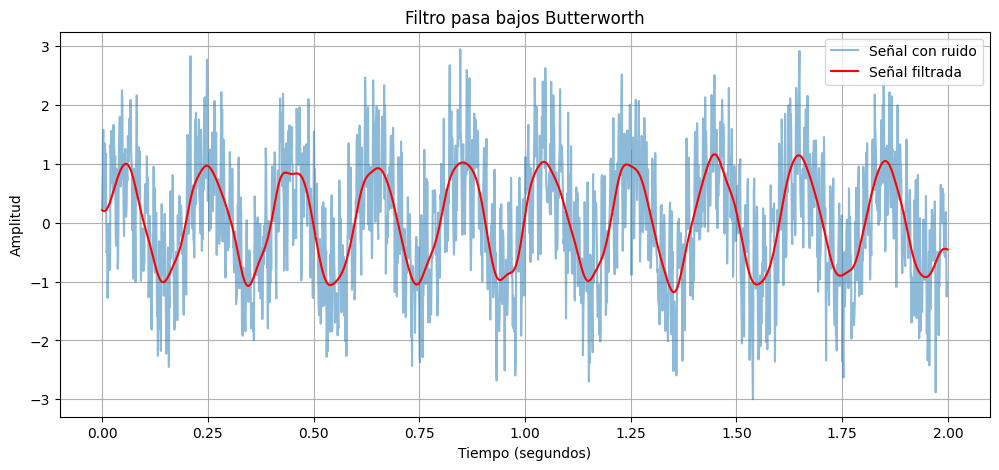

In [107]:

# DISEÑO DEL FILTRO PASA BAJOS

# Definir la frecuencia de corte
frecuencia_corte = 20

# Diseñar un filtro Butterworth IIR
orden = 4

b, a = signal.butter(
    orden,
    frecuencia_corte,
    btype='lowpass',
    fs=frecuencia_muestreo
)

# Aplicar el filtro a la señal con ruido
senal_pasa_bajos = signal.filtfilt(b, a, senal_ruidosa)

# Graficar la comparación
plt.figure(figsize=(12, 5))

plt.plot(t, senal_ruidosa, label="Señal con ruido", alpha=0.5)
plt.plot(t, senal_pasa_bajos, label="Señal filtrada", color="red")

plt.title("Filtro pasa bajos Butterworth")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.legend()
plt.grid()
plt.show()


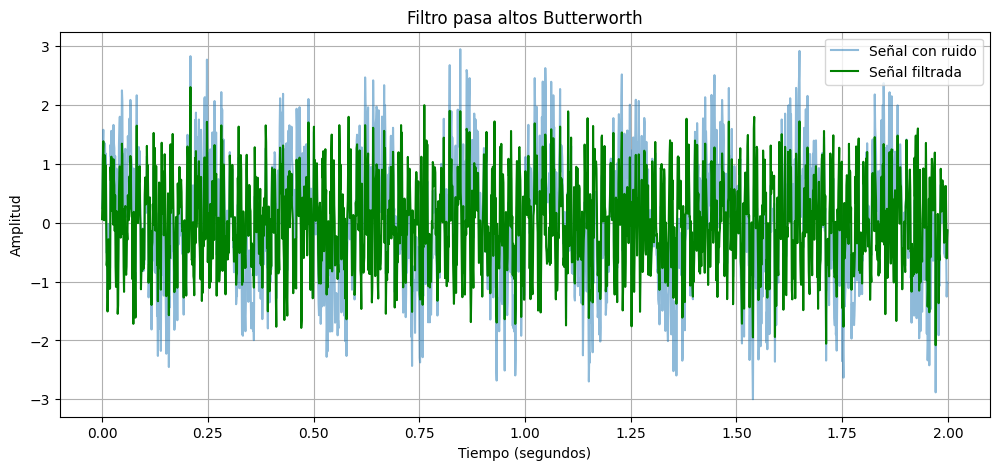

In [108]:

# DISEÑO DEL FILTRO PASA ALTOS

# Definir la frecuencia de corte
frecuencia_corte_alta = 30

# Diseñar un filtro Butterworth IIR
orden = 4

b_alto, a_alto = signal.butter(
    orden,
    frecuencia_corte_alta,
    btype='highpass',
    fs=frecuencia_muestreo
)

# Aplicar el filtro a la señal con ruido
senal_pasa_altos = signal.filtfilt(
    b_alto, a_alto, senal_ruidosa
)

# Graficar la comparación
plt.figure(figsize=(12, 5))

plt.plot(t, senal_ruidosa,
         label="Señal con ruido", alpha=0.5)

plt.plot(t, senal_pasa_altos,
         label="Señal filtrada", color="green")

plt.title("Filtro pasa altos Butterworth")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.legend()
plt.grid()
plt.show()


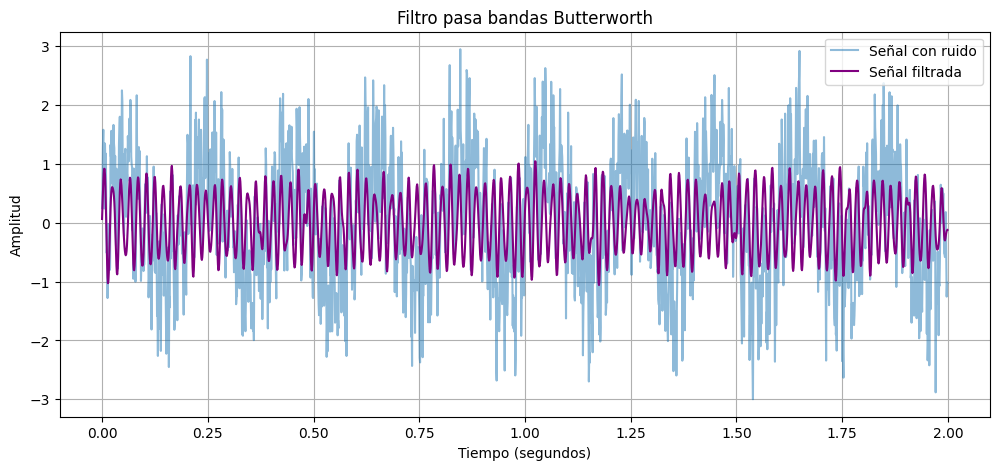

In [109]:

# DISEÑO DEL FILTRO PASA BANDAS

# Definir las frecuencias de corte
frecuencia_minima = 40
frecuencia_maxima = 100

# Diseñar un filtro Butterworth IIR
orden = 4

b_banda, a_banda = signal.butter(
    orden,
    [frecuencia_minima, frecuencia_maxima],
    btype='bandpass',
    fs=frecuencia_muestreo
)

# Aplicar el filtro a la señal con ruido
senal_pasa_bandas = signal.filtfilt(
    b_banda, a_banda, senal_ruidosa
)

# Graficar la comparación
plt.figure(figsize=(12, 5))

plt.plot(t, senal_ruidosa,
         label="Señal con ruido", alpha=0.5)

plt.plot(t, senal_pasa_bandas,
         label="Señal filtrada", color="purple")

plt.title("Filtro pasa bandas Butterworth")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.legend()
plt.grid()
plt.show()


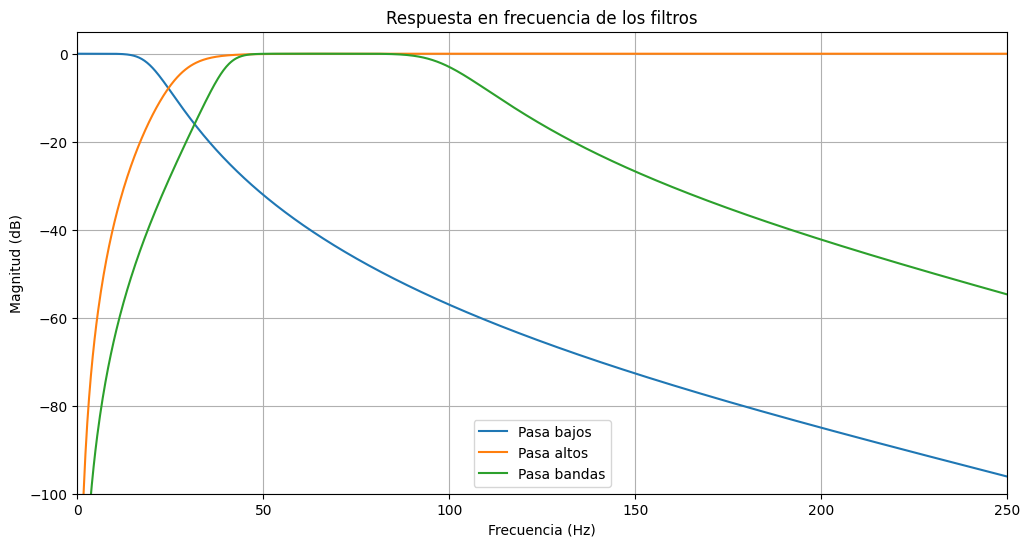

In [110]:

# RESPUESTA EN FRECUENCIA DE LOS TRES FILTROS

# Calcular la respuesta en frecuencia
frecuencias_bajas, respuesta_bajas = signal.freqz(
    b, a, worN=2048, fs=frecuencia_muestreo
)

frecuencias_altas, respuesta_altas = signal.freqz(
    b_alto, a_alto, worN=2048, fs=frecuencia_muestreo
)

frecuencias_bandas, respuesta_bandas = signal.freqz(
    b_banda, a_banda, worN=2048, fs=frecuencia_muestreo
)

# Convertir la magnitud a decibelios
plt.figure(figsize=(12, 6))

plt.plot(frecuencias_bajas,
         20 * np.log10(np.maximum(abs(respuesta_bajas), 1e-10)),
         label="Pasa bajos")

plt.plot(frecuencias_altas,
         20 * np.log10(np.maximum(abs(respuesta_altas), 1e-10)),
         label="Pasa altos")

plt.plot(frecuencias_bandas,
         20 * np.log10(np.maximum(abs(respuesta_bandas), 1e-10)),
         label="Pasa bandas")

plt.title("Respuesta en frecuencia de los filtros")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud (dB)")
plt.xlim(0, 250)
plt.ylim(-100, 5)
plt.legend()
plt.grid()
plt.show()


In [111]:

# DISEÑO DE FILTROS FIR

# Número de coeficientes del filtro
num_coeficientes = 101

# Filtro FIR pasa bajos
fir_bajo = signal.firwin(
    num_coeficientes,
    20,
    fs=frecuencia_muestreo,
    pass_zero='lowpass'
)

# Filtro FIR pasa altos
fir_alto = signal.firwin(
    num_coeficientes,
    30,
    fs=frecuencia_muestreo,
    pass_zero='highpass'
)

# Filtro FIR pasa bandas
fir_banda = signal.firwin(
    num_coeficientes,
    [40, 100],
    fs=frecuencia_muestreo,
    pass_zero='bandpass'
)

# Aplicar los filtros
senal_fir_bajo = signal.filtfilt(
    fir_bajo, [1.0], senal_ruidosa
)

senal_fir_alto = signal.filtfilt(
    fir_alto, [1.0], senal_ruidosa
)

senal_fir_banda = signal.filtfilt(
    fir_banda, [1.0], senal_ruidosa
)

print("Los tres filtros FIR se implementaron correctamente.")


Los tres filtros FIR se implementaron correctamente.


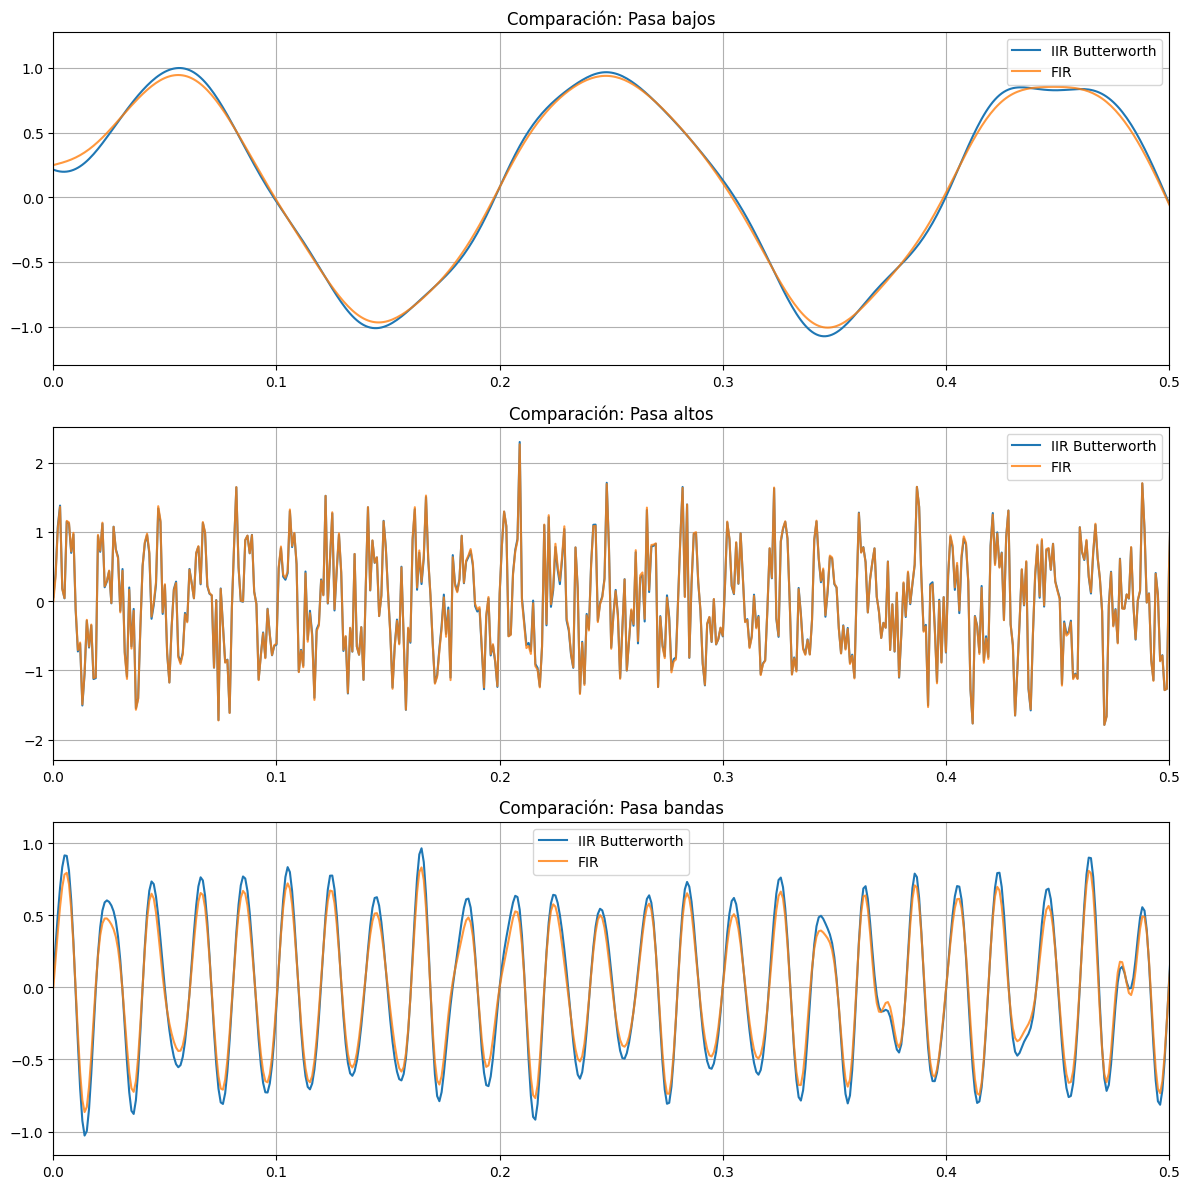

In [112]:

# COMPARACIÓN ENTRE FILTROS FIR E IIR

fig, ejes = plt.subplots(3, 1, figsize=(12, 12))

# Comparación pasa bajos
ejes[0].plot(t, senal_pasa_bajos,
             label="IIR Butterworth")
ejes[0].plot(t, senal_fir_bajo,
             label="FIR", alpha=0.8)
ejes[0].set_title("Comparación: Pasa bajos")
ejes[0].set_xlim(0, 0.5)
ejes[0].legend()
ejes[0].grid()

# Comparación pasa altos
ejes[1].plot(t, senal_pasa_altos,
             label="IIR Butterworth")
ejes[1].plot(t, senal_fir_alto,
             label="FIR", alpha=0.8)
ejes[1].set_title("Comparación: Pasa altos")
ejes[1].set_xlim(0, 0.5)
ejes[1].legend()
ejes[1].grid()

# Comparación pasa bandas
ejes[2].plot(t, senal_pasa_bandas,
             label="IIR Butterworth")
ejes[2].plot(t, senal_fir_banda,
             label="FIR", alpha=0.8)
ejes[2].set_title("Comparación: Pasa bandas")
ejes[2].set_xlim(0, 0.5)
ejes[2].legend()
ejes[2].grid()

plt.tight_layout()
plt.show()


In [113]:

# COMPARACIÓN DE LA DESVIACIÓN ESTÁNDAR

print("DESVIACIÓN ESTÁNDAR DE LAS SEÑALES")
print("-----------------------------------")

print("Señal original con ruido:",
      round(np.std(senal_ruidosa), 4))

print("Pasa bajos IIR:",
      round(np.std(senal_pasa_bajos), 4))

print("Pasa altos IIR:",
      round(np.std(senal_pasa_altos), 4))

print("Pasa bandas IIR:",
      round(np.std(senal_pasa_bandas), 4))

print("Pasa bajos FIR:",
      round(np.std(senal_fir_bajo), 4))

print("Pasa altos FIR:",
      round(np.std(senal_fir_alto), 4))

print("Pasa bandas FIR:",
      round(np.std(senal_fir_banda), 4))


DESVIACIÓN ESTÁNDAR DE LAS SEÑALES
-----------------------------------
Señal original con ruido: 1.0562
Pasa bajos IIR: 0.7222
Pasa altos IIR: 0.7599
Pasa bandas IIR: 0.5035
Pasa bajos FIR: 0.7054
Pasa altos FIR: 0.7649
Pasa bandas FIR: 0.4323
